# Session 2: several inputs, vectorized gradient descent

**Course link:** Machine Learning Specialization, Course 1 Week 2 (multiple features, vectorization, feature scaling, choosing the learning rate, feature engineering).

**Question:** does knowing more than the size of the budget tightening help predict TFP growth on countries the model has never seen?

**Same as Session 1:** the target (TFP growth from t−1 to t+2), the six hidden countries, and the baseline ("always predict the training average").

**New inputs:** ΔCAPB, the four thesis controls (each from the year before), and the consolidation episode flag (ΔCAPB ≥ 1.5 pp).

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. Rows that survive once the controls are added (Session 1 had 691):
2. On the six hidden countries, improvement over the baseline (Session 1: 1.2 %):
3. Which helps more, ΔCAPB or the four controls:
4. Hiding each of the 26 countries in turn, how many does the model win (Session 1: 13):
5. Effect per average episode with controls + flag (Session 1: −0.89 %, thesis: −1.50 %):
6. Learning rate α that works best with scaled inputs (0.001 / 0.01 / 0.1 / 1):
7. Does adding ΔCAPB² catch the threshold effect (yes / a little / no):

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

pd.set_option("display.width", 140)

df = pd.read_csv(DATA_URL)
print(df.shape)
df.head(3)

(780, 22)


,country,year,tfp,outputperworker,gfcf_public,gfcf_private,unemployment,real_compensation,exports,rd_intensity,...,long_rate,inflation,trade_open,net_exports_gdp,gini_disp,gini_disp_se,consumer_confidence,n_months,capb_main,dcapb_main
0,Austria,1995,83.3,73.1,3.9,21.773735,4.5,89.1,104.6,NaN,...,7.1,NaN,47.960351,-0.838734,26.7,0.80,-10.233333,3.0,-1.9,NaN
1,Austria,1996,83.2,74.4,3.7,22.258953,4.9,89.5,104.2,NaN,...,6.3,-0.723589,48.862365,-1.118985,26.2,0.79,-14.558333,12.0,-0.3,1.6
2,Austria,1997,83.5,75.5,3.0,22.523962,4.9,89.1,104.5,NaN,...,5.7,-1.311953,51.369113,-0.547645,26.1,0.85,-14.241667,12.0,1.5,1.8


## 1. Build the inputs

The controls are taken from the year before (t−1), as in the thesis, so they are known before the budget decision. The target also starts at t−1, so nothing from the future leaks in.

In [3]:
COUNTRY = "country"
YEAR    = "year"
DCAPB   = "dcapb_main"   # ΔCAPB, pp of GDP (+ = tightening)
TFP     = "tfp"
FLAG    = "episode"      # 1 if ΔCAPB >= 1.5 pp, else 0
SQUARE  = "dcapb_sq"     # ΔCAPB², used for the extra at the end
H = 2

df = df.sort_values([COUNTRY, YEAR]).copy()
df["log_tfp"] = np.log(df[TFP])

# Same target as Session 1: cumulative % TFP growth, t-1 -> t+2, within each country
lead = df.groupby(COUNTRY)["log_tfp"].shift(-H)
lag1 = df.groupby(COUNTRY)["log_tfp"].shift(1)
df["y"] = 100 * (lead - lag1)

# The four thesis controls from the data dictionary, one year back
CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
    df[lagged] = df.groupby(COUNTRY)[raw].shift(1)

df[FLAG] = (df[DCAPB] >= 1.5).astype(float)
df[SQUARE] = df[DCAPB] ** 2

# Session 1's rows, and the rows that also have all the controls
rows_s1 = df[[COUNTRY, YEAR, DCAPB, "y"]].dropna().copy()
data = df[[COUNTRY, YEAR, DCAPB, FLAG, SQUARE, "y"] + CONTROLS].dropna().reset_index(drop=True)

print("Session 1 rows:", len(rows_s1))
print("Session 2 rows:", len(data), "in", data[COUNTRY].nunique(), "countries,", data[YEAR].min(), "to", data[YEAR].max())
print("Episode-years in Session 2 rows:", int(data[FLAG].sum()))

Session 1 rows: 691
Session 2 rows: 669 in 26 countries, 1997 to 2022
Episode-years in Session 2 rows: 96


## 2. A data check before using the controls

A model will happily learn from bad numbers, so I looked at the controls first.

In [4]:
check = df.groupby(COUNTRY).agg(trade_open_median=("trade_open", "median"),
                                inflation_min=("inflation", "min"),
                                inflation_max=("inflation", "max")).round(1)
print(check.sort_values("trade_open_median").head(7))
print()
print("Poland:")
print(df.loc[(df[COUNTRY] == "Poland") & df[YEAR].between(2007, 2010), [YEAR, "inflation"]].round(1).to_string(index=False))

         trade_open_median  inflation_min  inflation_max
country                                                 
Hungary                0.4           -6.5           17.4
Sweden                 7.7           -7.6           12.7
Romania               11.2          -11.4           19.5
Denmark               11.7            0.1            7.7
Poland                17.8          -16.5           15.8
Italy                 46.8           -0.5           13.0
France                51.7           -1.6            6.9

Poland:
 year  inflation
 2007        5.4
 2008       12.2
 2009      -16.5
 2010       10.9


**This looks wrong.** The five countries with the lowest trade openness are all outside the euro: Hungary, Sweden, Romania, Denmark and Poland. Sweden at about 8 % of GDP is far too low, and each value looks too small by roughly that country's exchange rate. A likely cause is trade measured in euros divided by GDP measured in national currency. Poland's inflation of −16.5 % in 2009 also looks like an exchange-rate movement, not real inflation.

I have not confirmed the cause or changed the data here. The inputs below use the panel as it stands, and section 10 tests how much it matters. Since the thesis uses the same controls, this needs checking there too.

## 3. Vectorized gradient descent

Week 2's main idea: instead of a loop over inputs, `X @ w` multiplies the whole table of inputs by the vector of weights in one step. With one input, this reduces to the same model as Session 1.

In [5]:
def predict(X, w, b):
    return X @ w + b                         # f(x) = w·x + b for every row at once

def compute_cost(X, y, w, b):
    err = predict(X, w, b) - y
    return (err @ err) / (2 * len(y))

def compute_gradient(X, y, w, b):
    err = predict(X, w, b) - y
    return (X.T @ err) / len(y), err.mean()  # dJ/dw (one number per input), dJ/db

def gradient_descent(X, y, alpha, iters=5000):
    w, b = np.zeros(X.shape[1]), 0.0
    J_history = []
    for i in range(iters):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        J = compute_cost(X, y, w, b)
        J_history.append(J)
        if not np.isfinite(J) or J > 1e12:   # the cost has blown up: stop
            break
    return w, b, J_history

def fit_scaler(frame, inputs):
    # z-score settings: learned from the training rows you pass in, and nothing else
    return frame[inputs].mean().to_numpy(), frame[inputs].std(ddof=0).to_numpy()

def scale(frame, inputs, mu, sigma):
    return (frame[inputs].to_numpy() - mu) / sigma

def to_original_units(w_scaled, b_scaled, mu, sigma):
    # Turn weights on z-scores back into "per pp of GDP" etc.
    w = w_scaled / sigma
    return w, b_scaled - np.sum(w * mu)

## 4. Split by country, then scale using the training countries only

These are the same six hidden countries as Session 1. The mean and standard deviation come from the 20 training countries only. Using all countries would let information from the hidden ones leak into training.

In [6]:
rng = np.random.default_rng(42)
test_countries = rng.choice(rows_s1[COUNTRY].unique(), size=6, replace=False)
print("Hidden countries:", sorted(test_countries))

train = data[~data[COUNTRY].isin(test_countries)]
test  = data[ data[COUNTRY].isin(test_countries)]
print(f"Rows: train {len(train)}, test {len(test)}")

INPUTS_S1 = [DCAPB]
INPUTS_CONTROLS = CONTROLS
INPUTS_NO_FLAG = [DCAPB] + CONTROLS
INPUTS = [DCAPB] + CONTROLS + [FLAG]               # the Session 2 model
INPUTS_SQ = INPUTS + [SQUARE]                      # the extra

mu, sigma = fit_scaler(train, INPUTS)
X_train = scale(train, INPUTS, mu, sigma)
y_train = train["y"].to_numpy()

pd.DataFrame({"mean (train)": mu, "std (train)": sigma,
              "mean after scaling": X_train.mean(axis=0), "std after scaling": X_train.std(axis=0)},
             index=INPUTS).round(2)

Hidden countries: ['Belgium', 'Greece', 'Lithuania', 'Malta', 'Slovakia', 'Spain']
Rows: train 513, test 156


,mean (train),std (train),mean after scaling,std after scaling
dcapb_main,-0.13,2.18,0.0,1.0
gdp_growth_lag1,2.60,3.86,-0.0,1.0
debt_gdp_lag1,55.65,31.79,-0.0,1.0
inflation_lag1,2.25,3.99,-0.0,1.0
trade_open_lag1,73.33,63.97,0.0,1.0
episode,0.14,0.35,0.0,1.0


## 5. Why scaling matters

Debt and trade openness have much larger numbers than the other inputs. Without scaling, α has to stay tiny to avoid blowing up, and then learning is very slow.

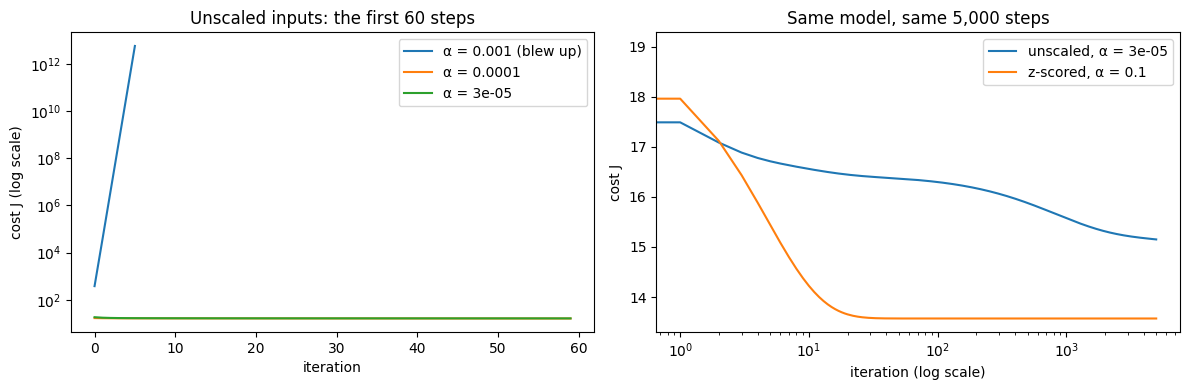

Cost after 5,000 steps: unscaled 15.151, z-scored 13.572


In [7]:
X_raw = train[INPUTS].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for a in [1e-3, 1e-4, 3e-5]:
    _, _, J = gradient_descent(X_raw, y_train, alpha=a, iters=500)
    label = f"α = {a:g}" + (" (blew up)" if len(J) < 500 or not np.isfinite(J[-1]) else "")
    ax[0].plot(J[:60], label=label)
ax[0].set_yscale("log"); ax[0].set_title("Unscaled inputs: the first 60 steps")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("cost J (log scale)"); ax[0].legend()

_, _, J_raw = gradient_descent(X_raw, y_train, alpha=3e-5, iters=5000)
_, _, J_std = gradient_descent(X_train, y_train, alpha=0.1, iters=5000)
ax[1].plot(J_raw, label="unscaled, α = 3e-05")
ax[1].plot(J_std, label="z-scored, α = 0.1")
ax[1].set_xscale("log"); ax[1].set_title("Same model, same 5,000 steps")
ax[1].set_xlabel("iteration (log scale)"); ax[1].set_ylabel("cost J"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Cost after 5,000 steps: unscaled {J_raw[-1]:.3f}, z-scored {J_std[-1]:.3f}")

## 6. Pick α by trying values about ×3 apart

The rule uses **training data only**, never the hidden countries: take the largest α whose cost falls at every step. A larger α learns faster until it becomes unstable.

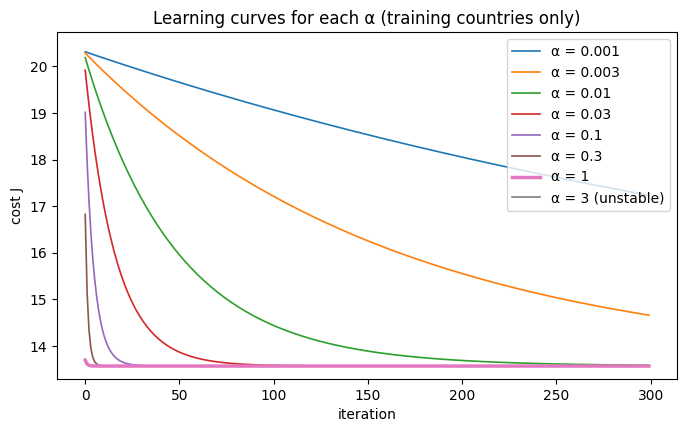

α = 0.001  cost after 300 steps: 17.24
α = 0.003  cost after 300 steps: 14.66
α = 0.01   cost after 300 steps: 13.59
α = 0.03   cost after 300 steps: 13.57
α = 0.1    cost after 300 steps: 13.57
α = 0.3    cost after 300 steps: 13.57
α = 1      cost after 300 steps: 13.57
α = 3      cost after  11 steps: 2.382e+12

Chosen α: 1.0


In [8]:
ALPHAS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]

def pick_alpha(X, y, iters=300):
    curves, best = {}, None
    for a in ALPHAS:
        _, _, J = gradient_descent(X, y, alpha=a, iters=iters)
        curves[a] = J
        if len(J) == iters and np.all(np.diff(J) <= 1e-12):   # finished, and never went up
            best = a
    return best, curves

alpha, curves = pick_alpha(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 4.5))
for a, J in curves.items():
    stable = len(J) == 300 and np.all(np.diff(J) <= 1e-12)
    ax.plot(J, label=f"α = {a:g}" + ("" if stable else " (unstable)"), lw=2.5 if a == alpha else 1.2)
ax.set_ylim(min(curves[alpha]) * 0.98, compute_cost(X_train, y_train, np.zeros(X_train.shape[1]), 0.0) * 1.02)
ax.set_title("Learning curves for each α (training countries only)")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J"); ax.legend(); plt.show()

for a, J in curves.items():
    print(f"α = {a:<6g} cost after {len(J):>3} steps: {J[-1]:.4g}")
print("\nChosen α:", alpha)

## 7. Train the model and check it against scikit-learn

The learning curve should fall and then go flat. `LinearRegression` solves the same problem directly, so the two sets of weights should match. I fit it on the unscaled inputs, which also shows that scaling changes how fast we get there, not where we end up.

                 gradient descent  scikit-learn
dcapb_main                -0.1407       -0.1407
gdp_growth_lag1            0.0736        0.0736
debt_gdp_lag1             -0.0218       -0.0218
inflation_lag1             0.0401        0.0401
trade_open_lag1           -0.0100       -0.0100
episode                   -0.3379       -0.3379
intercept b                5.1980        5.1980

Largest gap between the two: 4.4e-15


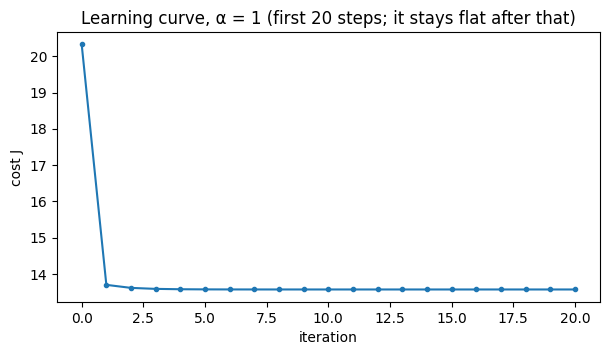

Cost at the start: 20.3256, after 20 steps: 13.5720, after 5000 steps: 13.5720


In [9]:
w_s, b_s, J_hist = gradient_descent(X_train, y_train, alpha=alpha, iters=5000)
w_gd, b_gd = to_original_units(w_s, b_s, mu, sigma)

sk = LinearRegression().fit(train[INPUTS].to_numpy(), y_train)

print(pd.DataFrame({"gradient descent": np.r_[w_gd, b_gd], "scikit-learn": np.r_[sk.coef_, sk.intercept_]},
                   index=INPUTS + ["intercept b"]).round(4))
print("\nLargest gap between the two:", f"{np.max(np.abs(np.r_[w_gd, b_gd] - np.r_[sk.coef_, sk.intercept_])):.1e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
J_start = compute_cost(X_train, y_train, np.zeros(X_train.shape[1]), 0.0)   # cost before any training
ax.plot(range(0, 21), [J_start] + J_hist[:20], marker="o", ms=3)
ax.set_title(f"Learning curve, α = {alpha:g} (first 20 steps; it stays flat after that)")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J"); plt.show()
print(f"Cost at the start: {J_start:.4f}, after 20 steps: {J_hist[19]:.4f}, after 5000 steps: {J_hist[-1]:.4f}")

## 8. The unseen-country test

The baseline is the same as in Session 1. Adding the controls removes some rows, so Session 1's model is also re-run **on the same rows**. Otherwise the comparison would not be fair.

In [10]:
MODELS = {
    "Session 1: ΔCAPB only": INPUTS_S1,
    "Controls only": INPUTS_CONTROLS,
    "ΔCAPB + controls": INPUTS_NO_FLAG,
    "Session 2: ΔCAPB + controls + flag": INPUTS,
    "Extra: Session 2 + ΔCAPB²": INPUTS_SQ,
}

def fit_gd(tr, inputs):
    # z-score on the rows passed in, choose α on them, train, return weights in original units
    m, s = fit_scaler(tr, inputs)
    X, y = scale(tr, inputs, m, s), tr["y"].to_numpy()
    a, _ = pick_alpha(X, y)
    w, b, _ = gradient_descent(X, y, alpha=a, iters=5000)
    return (*to_original_units(w, b, m, s), a)

def evaluate(tr, te, inputs):
    w, b, a = fit_gd(tr, inputs)
    y_te = te["y"].to_numpy()
    mse_model = np.mean((predict(te[inputs].to_numpy(), w, b) - y_te) ** 2)
    mse_base  = np.mean((tr["y"].mean() - y_te) ** 2)
    return mse_model, mse_base, a

# Session 1's exact number, on Session 1's own rows, as a check
tr1 = rows_s1[~rows_s1[COUNTRY].isin(test_countries)]
te1 = rows_s1[ rows_s1[COUNTRY].isin(test_countries)]
m1, b1, _ = evaluate(tr1, te1, INPUTS_S1)
print(f"Session 1 on its own rows: model {m1:.2f}, baseline {b1:.2f}, improvement {100*(1-m1/b1):.1f} %\n")

table = []
for name, inputs in MODELS.items():
    m, b, a = evaluate(train, test, inputs)
    table.append({"model": name, "α": a, "error": round(m, 2), "baseline error": round(b, 2),
                  "improvement %": round(100 * (1 - m / b), 1)})
six = pd.DataFrame(table).set_index("model")
six

Session 1 on its own rows: model 30.34, baseline 30.72, improvement 1.2 %



,α,error,baseline error,improvement %
model,,,,
Session 1: ΔCAPB only,1.0,30.39,30.74,1.1
Controls only,1.0,27.87,30.74,9.3
ΔCAPB + controls,1.0,27.62,30.74,10.1
Session 2: ΔCAPB + controls + flag,1.0,27.67,30.74,10.0
Extra: Session 2 + ΔCAPB²,1.0,27.71,30.74,9.8


### Is that split representative? Hide every country in turn

Six countries is a small test, so I also repeat Session 1's leave-one-country-out test. Each country is hidden once, and the scaling and training are redone without it. **Wins** counts the countries where the model beats the baseline. **Overall** adds up all the errors, so a country that goes badly wrong counts for what it costs.

In [11]:
def leave_one_out(frame, inputs):
    rows = []
    for c in frame[COUNTRY].unique():
        tr, te = frame[frame[COUNTRY] != c], frame[frame[COUNTRY] == c]
        m, b, _ = evaluate(tr, te, inputs)
        rows.append({COUNTRY: c, "n": len(te), "model": m, "base": b})
    return pd.DataFrame(rows).set_index(COUNTRY)

loo = {name: leave_one_out(data, inputs) for name, inputs in MODELS.items()}
s1_own = leave_one_out(rows_s1, INPUTS_S1)

def loo_summary(r):
    return {"wins": int((r["model"] < r["base"]).sum()), "out of": len(r),
            "overall improvement %": round(100 * (1 - (r["model"] * r["n"]).sum() / (r["base"] * r["n"]).sum()), 1)}

print("Session 1 on its own rows:", loo_summary(s1_own), "\n")
loo_table = pd.DataFrame({name: loo_summary(r) for name, r in loo.items()}).T
loo_table

Session 1 on its own rows: {'wins': 13, 'out of': 26, 'overall improvement %': np.float64(0.4)} 



,wins,out of,overall improvement %
Session 1: ΔCAPB only,15.0,26.0,0.5
Controls only,17.0,26.0,-1.1
ΔCAPB + controls,16.0,26.0,-0.8
Session 2: ΔCAPB + controls + flag,16.0,26.0,-1.1
Extra: Session 2 + ΔCAPB²,16.0,26.0,-1.6


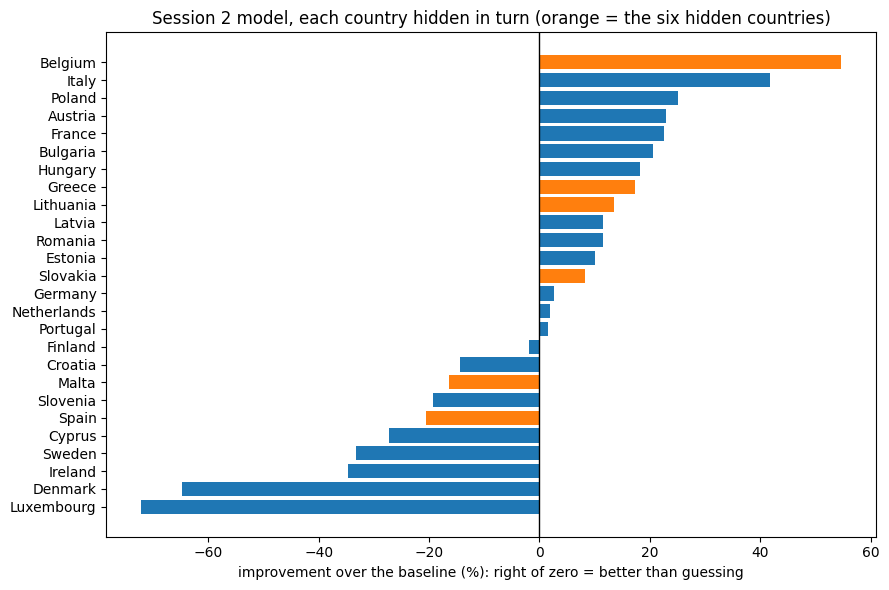

In [12]:
r = loo["Session 2: ΔCAPB + controls + flag"]
imp = (100 * (1 - r["model"] / r["base"])).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
hidden = imp.index.isin(test_countries)
ax.barh(imp.index, imp.values, color=np.where(hidden, "tab:orange", "tab:blue"))
ax.axvline(0, color="black", lw=1)
ax.set_title("Session 2 model, each country hidden in turn (orange = the six hidden countries)")
ax.set_xlabel("improvement over the baseline (%): right of zero = better than guessing")
plt.tight_layout(); plt.show()

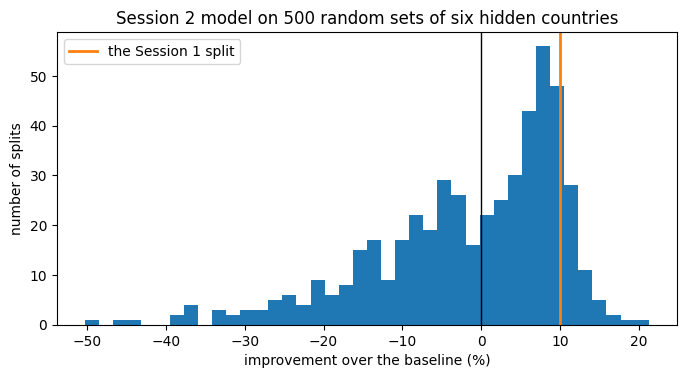

Session 1: ΔCAPB only: median 0.7 %, middle 90 % from -2.2 to 1.9 %, beats baseline in 69 % of splits
Session 2: ΔCAPB + controls + flag: median 1.6 %, middle 90 % from -24.7 to 12.0 %, beats baseline in 54 % of splits


In [13]:
# How lucky is one split? Try 500 random sets of six hidden countries.
# LinearRegression gives the same answer as gradient descent (section 7) and is much faster here.
def fast_improvement(tr, te, inputs):
    fit = LinearRegression().fit(tr[inputs].to_numpy(), tr["y"].to_numpy())
    p = fit.intercept_ + te[inputs].to_numpy() @ fit.coef_
    y_te = te["y"].to_numpy()
    return 100 * (1 - np.mean((p - y_te) ** 2) / np.mean((tr["y"].mean() - y_te) ** 2))

rng_many = np.random.default_rng(0)
countries = data[COUNTRY].unique()
many = {"Session 1: ΔCAPB only": [], "Session 2: ΔCAPB + controls + flag": []}
for i in range(500):
    h = rng_many.choice(countries, size=6, replace=False)
    tr, te = data[~data[COUNTRY].isin(h)], data[data[COUNTRY].isin(h)]
    for name in many:
        many[name].append(fast_improvement(tr, te, MODELS[name]))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(many["Session 2: ΔCAPB + controls + flag"], bins=40)
ax.axvline(0, color="black", lw=1)
ax.axvline(six.loc["Session 2: ΔCAPB + controls + flag", "improvement %"], color="tab:orange", lw=2, label="the Session 1 split")
ax.set_title("Session 2 model on 500 random sets of six hidden countries")
ax.set_xlabel("improvement over the baseline (%)"); ax.set_ylabel("number of splits"); ax.legend(); plt.show()

for name, v in many.items():
    v = np.array(v)
    print(f"{name}: median {np.median(v):.1f} %, middle 90 % from {np.percentile(v, 5):.1f} to {np.percentile(v, 95):.1f} %, beats baseline in {100*np.mean(v > 0):.0f} % of splits")

## 9. The effect per episode, compared with the thesis

This is the Session 1 fixed-effects step again, now with the extra inputs. Each country and year average is removed, so the model compares a country with itself over time. An average episode then adds the ΔCAPB slope × its size, plus the flag's jump. The t-values use country-clustered standard errors, like the thesis.

In [14]:
def demean_two_way(frame, cols):
    out = pd.DataFrame(index=frame.index)
    for col in cols:
        v = frame[col].copy()
        for i in range(200):
            v = v - v.groupby(frame[COUNTRY]).transform("mean")
            v = v - v.groupby(frame[YEAR]).transform("mean")
        out[col] = v
    return out

def fe_fit(frame, inputs):
    # Same gradient descent as before, on the demeaned data
    fe = demean_two_way(frame, inputs + ["y"])
    w, b, a = fit_gd(fe, inputs)
    ols = sm.OLS(fe["y"], fe[inputs]).fit(cov_type="cluster", cov_kwds={"groups": frame[COUNTRY].to_numpy()})
    res = fe["y"] - predict(fe[inputs].to_numpy(), w, b)
    r2 = 1 - np.sum(res ** 2) / np.sum(fe["y"] ** 2)
    return pd.Series(w, index=inputs), ols.tvalues, r2, np.max(np.abs(w - ols.params.to_numpy()))

def episode_effect(w, frame):
    ep = frame[frame[FLAG] == 1]
    return (w.get(DCAPB, 0) * ep[DCAPB].mean() + w.get(FLAG, 0) + w.get(SQUARE, 0) * ep[SQUARE].mean())

FE_MODELS = {
    "Session 1: ΔCAPB only": INPUTS_S1,
    "ΔCAPB + controls": INPUTS_NO_FLAG,
    "Flag + controls (the thesis design)": CONTROLS + [FLAG],
    "Session 2: ΔCAPB + controls + flag": INPUTS,
    "Extra: Session 2 + ΔCAPB²": INPUTS_SQ,
}

rows = []
fe_results = {}
for name, inputs in FE_MODELS.items():
    w, t, r2, gap = fe_fit(data, inputs)
    fe_results[name] = (w, t)
    rows.append({"model": name,
                 "ΔCAPB slope": round(w.get(DCAPB, np.nan), 3), "t": round(t.get(DCAPB, np.nan), 1),
                 "flag": round(w.get(FLAG, np.nan), 3), "t ": round(t.get(FLAG, np.nan), 1),
                 "ΔCAPB²": round(w.get(SQUARE, np.nan), 3), "t  ": round(t.get(SQUARE, np.nan), 1),
                 "within R²": round(r2, 3), "effect per episode %": round(episode_effect(w, data), 2),
                 "gap to OLS": f"{gap:.0e}"})
effects = pd.DataFrame(rows).set_index("model")
ep = data[data[FLAG] == 1]
print(f"Episode-years: {len(ep)}, average size {ep[DCAPB].mean():.2f} pp. Thesis (LP, h = 2): -1.50 %")
effects

Episode-years: 96, average size 3.31 pp. Thesis (LP, h = 2): -1.50 %


,ΔCAPB slope,t,flag,t,ΔCAPB²,t,within R²,effect per episode %,gap to OLS
model,,,,,,,,,
Session 1: ΔCAPB only,-0.281,-3.0,NaN,NaN,NaN,NaN,0.024,-0.93,0e+00
ΔCAPB + controls,-0.290,-3.7,NaN,NaN,NaN,NaN,0.033,-0.96,6e-17
Flag + controls (the thesis design),NaN,NaN,-1.492,-3.4,NaN,NaN,0.025,-1.49,2e-16
Session 2: ΔCAPB + controls + flag,-0.233,-3.2,-0.593,-1.4,NaN,NaN,0.035,-1.36,2e-16
Extra: Session 2 + ΔCAPB²,-0.254,-3.3,-0.283,-0.6,-0.02,-5.4,0.046,-1.46,3e-16


## 10. How much do the suspicious controls matter?

The same tests without `trade_open` and `inflation`, the two controls flagged in section 2.

In [15]:
CLEAN = [DCAPB, "gdp_growth_lag1", "debt_gdp_lag1", FLAG]
m, b, _ = evaluate(train, test, CLEAN)
print(f"Six hidden countries: improvement {100*(1-m/b):.1f} %")
print("Every country hidden in turn:", loo_summary(leave_one_out(data, CLEAN)))
w_clean, t_clean, _, _ = fe_fit(data, CLEAN)
print(f"Effect per episode: {episode_effect(w_clean, data):.2f} %")
w_flag, t_flag, _, _ = fe_fit(data, ["gdp_growth_lag1", "debt_gdp_lag1", FLAG])
print(f"Thesis design (flag + the two remaining controls): {episode_effect(w_flag, data):.2f} % (t = {t_flag[FLAG]:.1f})")

Six hidden countries: improvement 10.3 %


Every country hidden in turn: {'wins': 15, 'out of': 26, 'overall improvement %': np.float64(2.7)}


Effect per episode: -1.35 %


Thesis design (flag + the two remaining controls): -1.48 % (t = -3.2)


## 11. Extra: does ΔCAPB² catch the threshold?

The thesis effect looks like a threshold: little happens until a tightening gets large. A squared term can only draw a smooth curve, and that curve treats a big loosening and a big tightening alike. So I plot the actual averages next to what each model draws, and re-check the result without Ireland's 2010–11 bank-rescue years (ΔCAPB of −18.8 and +18.2).

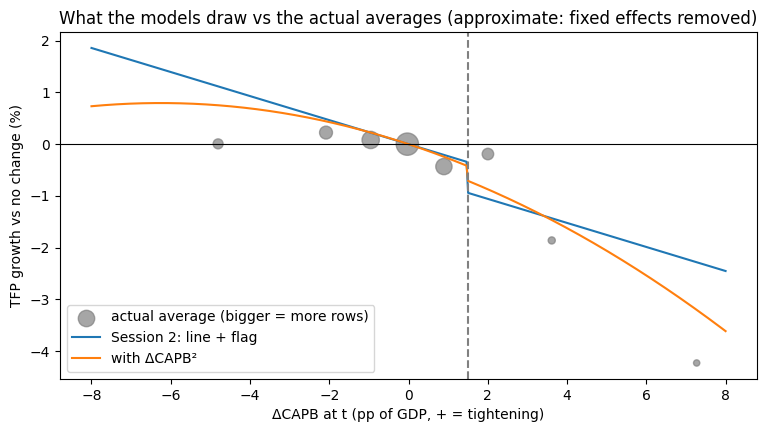

                  x     y    n
dcapb_main                    
[-20.0, -3.0) -4.80  0.01   43
[-3.0, -1.5)  -2.08  0.22   72
[-1.5, -0.5)  -0.96  0.08  129
[-0.5, 0.5)   -0.03  0.00  215
[0.5, 1.5)     0.89 -0.43  114
[1.5, 3.0)     2.00 -0.19   57
[3.0, 5.0)     3.61 -1.86   22
[5.0, 20.0)    7.27 -4.23   17



Without Ireland 2010-11: ΔCAPB² = -0.038 (t = -1.9), flag = 0.103 (t = 0.2), effect per episode -1.41 %


In [16]:
# Actual averages: TFP growth by size of ΔCAPB, with country and year averages removed
fe_y = demean_two_way(data, ["y"])["y"]
bins = [-20, -3, -1.5, -0.5, 0.5, 1.5, 3, 5, 20]
groups = pd.cut(data[DCAPB], bins, right=False)
avg = pd.DataFrame({"x": data[DCAPB], "y": fe_y}).groupby(groups, observed=True).agg(x=("x", "mean"), y=("y", "mean"), n=("y", "size"))
reference = avg.loc[avg.index.map(lambda i: i.left == -0.5), "y"].iloc[0]
avg["y"] = avg["y"] - reference     # measured against "no real change in the budget"

w2, _ = fe_results["Session 2: ΔCAPB + controls + flag"]
w3, _ = fe_results["Extra: Session 2 + ΔCAPB²"]
xs = np.linspace(-8, 8, 400)
line = w2[DCAPB] * xs + w2[FLAG] * (xs >= 1.5)
curve = w3[DCAPB] * xs + w3[FLAG] * (xs >= 1.5) + w3[SQUARE] * xs ** 2

fig, ax = plt.subplots(figsize=(9, 4.5))
in_view = avg[avg["x"].between(-8, 8)]
ax.scatter(in_view["x"], in_view["y"], s=in_view["n"] * 1.2, color="grey", alpha=0.7, label="actual average (bigger = more rows)")
ax.plot(xs, line, label="Session 2: line + flag")
ax.plot(xs, curve, label="with ΔCAPB²")
ax.axvline(1.5, ls="--", color="grey"); ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("ΔCAPB at t (pp of GDP, + = tightening)"); ax.set_ylabel("TFP growth vs no change (%)")
ax.set_title("What the models draw vs the actual averages (approximate: fixed effects removed)")
ax.legend(); plt.show()
print(avg.round(2))

no_ireland = data[~((data[COUNTRY] == "Ireland") & data[YEAR].isin([2010, 2011]))].reset_index(drop=True)
wq, tq, _, _ = fe_fit(no_ireland, INPUTS_SQ)
print(f"\nWithout Ireland 2010-11: ΔCAPB² = {wq[SQUARE]:.3f} (t = {tq[SQUARE]:.1f}), flag = {wq[FLAG]:.3f} (t = {tq[FLAG]:.1f}), effect per episode {episode_effect(wq, no_ireland):.2f} %")

# Learning log, Session 2 (2 Nov 2026)

**Course:** Machine Learning Specialization, Course 1 Week 2 (multiple features, vectorization, feature scaling, choosing the learning rate, feature engineering)

**Setup:** ΔCAPB + four lagged thesis controls + episode flag (ΔCAPB ≥ 1.5 pp). 669 rows: the controls cost 22 rows, because inflation starts in 1996 and its one-year lag therefore starts in 1997. Same target, same six hidden countries and same baseline as Session 1.

**Method**
- Z-score scaling uses the training countries only, and is redone inside every leave-one-out fold.
- Without scaling, α has to stay tiny and training is slow: after 5,000 steps the cost is 15.15, versus 13.57 with scaling.
- α values about ×3 apart, chosen on training data only: 1.0 is the largest whose cost falls at every step, and 3.0 blows up.
- Vectorized gradient descent matches scikit-learn's `LinearRegression` (largest gap 4e-15).

**Prediction: no reliable gain**

| Model | Six hidden countries: better than baseline | Each country hidden in turn: wins | Each country hidden in turn: overall |
|---|---|---|---|
| Session 1 model, on its own 691 rows | 1.2 % | 13 of 26 | +0.4 % |
| Session 1 model, on the same 669 rows | 1.1 % | 15 of 26 | +0.5 % |
| Controls only | 9.3 % | 17 of 26 | −1.1 % |
| ΔCAPB + controls | 10.1 % | 16 of 26 | −0.8 % |
| **Session 2: ΔCAPB + controls + flag** | **10.0 %** | **16 of 26** | **−1.1 %** |
| Session 2 + ΔCAPB² | 9.8 % | 16 of 26 | −1.6 % |

- The 10 % is mostly a lucky split. Over 500 random sets of six hidden countries, the median is +1.6 %, the middle 90 % runs from −24.7 % to +12.0 %, and the model beats the baseline in only 54 % of them.
- It helps some countries a lot (Belgium, Italy) and hurts others badly (Luxembourg, Denmark, Ireland, Sweden). Overall, those losses cancel the gains.
- The controls do the predicting. Adding ΔCAPB and the flag to them changes almost nothing.

**Effect per episode: closer to the thesis (−1.50 %)**
- On the same rows, the effect moves from −0.93 % (ΔCAPB only) to −1.36 % (Session 2). Session 1's −0.89 % was on its own rows.
- Flag + controls, the thesis design, gives −1.49 % (t = −3.4), almost exactly the thesis number. This is not a full replication: it is one horizon, on this sample.
- In the Session 2 model, ΔCAPB stays significant (−0.233, t = −3.2) while the flag does not (−0.593, t = −1.4). ΔCAPB and the flag partly measure the same thing.

**Extra: ΔCAPB² catches the shape only partly, and does not help prediction**
- Within the sample, it looks useful: ΔCAPB² = −0.020 (t = −5.4), the flag shrinks to −0.283 (t = −0.6), and the effect becomes −1.46 %.
- But much of that comes from Ireland 2010–11: without those two years, ΔCAPB² has t = −1.9.
- The actual averages are flat for loosening and fall sharply only from about 3 pp of tightening (−0.19 % at 1.5–3 pp, −1.86 % at 3–5 pp, −4.23 % above 5 pp). A parabola wrongly says big loosening hurts too, and the 1.5 pp flag may sit too low to mark the real break.
- On unseen countries it is no better: 9.8 %, 16 of 26, −1.6 % overall.

**Data problem found: check this in the thesis too**
- `trade_open` is far too low in five non-euro countries (median: Hungary 0.4, Sweden 7.7, Romania 11.2, Denmark 11.7, Poland 17.8). The values look too small by about the exchange rate, which would fit euro trade divided by national-currency GDP.
- `inflation` also looks off in non-euro countries, for example Poland 2009 at −16.5 %, possibly because it reflects exchange-rate moves.
- This is a pattern in the numbers. I have not confirmed the cause or changed the data.
- Without these two controls, the Session 2 model goes from −1.1 % to +2.7 % overall (15 of 26 wins) on the hide-each-country test, and its effect barely moves (−1.35 %). The thesis-design estimate barely moves either (−1.48 %). Because I chose this test after seeing the results, the +2.7 % is a warning about the data, not a better model.

**Main lessons**
- Check one test against others: a single split can make a model look better than it is.
- Controls improve the effect estimate, but not reliably the prediction. A better estimate of a cause is not the same as a better predictor.
- ML still adds nothing reliable over the econometrics.

**Next:** check `trade_open` and `inflation` at the source, then Course 1 Week 3 (logistic regression): which episodes are followed by below-median TFP growth?